# FloodWatch — Model Training (Fixed)

Trains the Random Forest classifier that tells the three drainage states apart:
**normal**, **flood**, **blockage**.

### What was wrong with `phase2_model_training.ipynb`
1. **`NameError: name 'plt' is not defined`** — the confusion-matrix and feature-importance
   cells call `plt.title(...)` / `plt.show()` but `matplotlib.pyplot` was never imported anywhere
   in the notebook. The notebook could not run end-to-end (it always died at the confusion-matrix cell),
   so `model.joblib` / `encoder.joblib` never got regenerated from that notebook.
2. **Water level range didn't match the real sensor.** The HC-SR04 nodes report `0–37` cm max, but the
   synthetic data clipped water levels to `0–35`. Readings near the true top of the sensor's range
   (36–37 cm) were never seen during training, so they fell outside the model's learned distribution.
3. **Class boundaries overlapped more than necessary.** `flood` and `blockage` both used
   `water_level1` in the same `18–35` band with only soft, noisy separation, which made the two
   easiest to confuse for each other. This version keeps the same 8 features (so the server code
   doesn't need to change) but gives each class a clearer physical signature.

Everything below keeps the exact same **feature set, order, and label names** used by
`server/config.py` (`ML_FEATURES`) and `server/prediction.py`, so the output `model.joblib` /
`encoder.joblib` are drop-in compatible with the existing Flask server — no other code changes needed.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt   # <-- this import was missing in phase2_model_training.ipynb

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
)
import joblib

SEED = 42
np.random.seed(SEED)

OUTPUT_DIR = "manhole_model_output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Deploy target used by the Flask server (server/models/). Matches train_model.py's behaviour.
SERVER_MODELS_DIR = os.path.join("..", "server", "models")


## 1. Sensor & feature configuration

`SENSOR_MIN` / `SENSOR_MAX` reflect the **real hardware range** (HC-SR04 water level, 0–37 cm,
per the project's manhole setup) — every synthetic reading is generated and clipped inside this
range so the model never trains on values the sensor can't actually produce, and never fails to
learn values near the real ceiling (36–37 cm).

In [3]:
SENSOR_MIN = 0.0
SENSOR_MAX = 37.0   # real HC-SR04 max for this deployment (per hardware spec)

FEATURES = [
    "water_level_node1",
    "water_level_node2",
    "level_diff",
    "rise_rate_node1",
    "rise_rate_node2",
    "precipitationIntensity",
    "precipitationProbability",
    "precipitationIntensity_next_hour",
]
TARGET = "label"
CLASSES = ["normal", "flood", "blockage"]   # kept identical to server/config.py's fallback map

N_NORMAL = 3500
N_FLOOD = 2000
N_BLOCKAGE = 2000


## 2. Synthetic data generators

Each class gets a **distinct physical signature** so the classifier has a real pattern to learn
instead of only noisy overlap:

| Class | Node 1 vs Node 2 | `level_diff` | `rise_rate` | Rain |
|---|---|---|---|---|
| **normal** | both low/moderate, track each other | small | low, occasionally negative (draining) | any |
| **flood** | both high, close to the 37 cm ceiling, rising together | small | high on both nodes | heavy rain, high probability |
| **blockage** | node 1 backs up near the ceiling, node 2 stays low because water can't pass through | large | node 1 rises fast, node 2 stays flat/near zero | can happen with or without rain |

Every generator draws a mix of sub-cases (e.g. "dry normal" vs "light-rain normal", "onset flood" vs
"severe flood", "partial blockage" vs "severe blockage") so the model sees realistic variety
*within* each label, without ever mixing labels together.

In [4]:
def _clip_level(x):
    return np.clip(x, SENSOR_MIN, SENSOR_MAX)


def generate_normal(n):
    rows = []
    for _ in range(n):
        # mix of dry conditions and light/moderate rain, including a "draining" sub-case
        draining = np.random.rand() < 0.15

        rain_probability = np.random.uniform(0, 45)
        precipitationIntensity = max(0, rain_probability * 0.08 + np.random.normal(0, 1))
        precipitationIntensity_next = max(0, precipitationIntensity + np.random.normal(0, 1))

        if draining:
            # water level was up, now receding — negative rise rate, low rain
            rise_rate1 = np.random.uniform(-2.0, -0.1)
            rise_rate2 = rise_rate1 + np.random.uniform(-0.3, 0.3)
            base_level = np.random.uniform(6, 16)
        else:
            rise_rate1 = max(0, precipitationIntensity * 0.15 + np.random.uniform(0, 1))
            rise_rate2 = max(0, rise_rate1 + np.random.uniform(-0.3, 0.3))
            base_level = np.random.uniform(1, 12)

        water_level1 = _clip_level(base_level + rise_rate1 * np.random.uniform(0.2, 0.5))
        water_level2 = _clip_level(water_level1 + np.random.uniform(-1.5, 1.5))
        # normal always stays comfortably below the flood/blockage band
        water_level1 = min(water_level1, 17.0)
        water_level2 = min(water_level2, 17.0)

        level_diff = water_level1 - water_level2

        rows.append([water_level1, water_level2, level_diff, rise_rate1, rise_rate2,
                     precipitationIntensity, rain_probability, precipitationIntensity_next, "normal"])

    return pd.DataFrame(rows, columns=FEATURES + [TARGET])


def generate_flood(n):
    rows = []
    for _ in range(n):
        # mix of "onset" flood (just crossed the threshold) and "severe/cloudburst" flood
        severe = np.random.rand() < 0.45

        if severe:
            rain_probability = np.random.uniform(95, 100)
            precipitationIntensity = np.random.uniform(60, 120)
            rise_rate1 = np.random.uniform(15, 25)
        else:
            rain_probability = np.random.uniform(75, 96)
            precipitationIntensity = np.random.uniform(25, 65)
            rise_rate1 = precipitationIntensity * 0.25 + np.random.uniform(2, 6)

        precipitationIntensity_next = np.clip(
            precipitationIntensity + np.random.uniform(-5, 20), 20, 120
        )
        rise_rate2 = rise_rate1 + np.random.uniform(-1, 1)

        # flood = BOTH nodes near the sensor ceiling, rising together
        water_level1 = _clip_level(np.random.uniform(24, SENSOR_MAX))
        water_level2 = _clip_level(water_level1 + np.random.uniform(-2, 2))
        # keep the two nodes close together (small diff) — that's what separates flood from blockage
        water_level2 = _clip_level(water_level1 - abs(np.random.uniform(-2.5, 2.5)))

        level_diff = water_level1 - water_level2

        rows.append([water_level1, water_level2, level_diff, rise_rate1, rise_rate2,
                     precipitationIntensity, rain_probability, precipitationIntensity_next, "flood"])

    return pd.DataFrame(rows, columns=FEATURES + [TARGET])


def generate_blockage(n):
    rows = []
    for _ in range(n):
        # mix of partial and severe blockage
        severe = np.random.rand() < 0.5

        rain_probability = np.random.uniform(0, 100)
        precipitationIntensity = np.random.uniform(0, 45)
        precipitationIntensity_next = max(0, precipitationIntensity + np.random.uniform(-5, 10))

        # node 1 (upstream of the blockage) backs up toward the ceiling
        water_level1 = _clip_level(np.random.uniform(20, SENSOR_MAX))
        if severe:
            blockage_gap = np.random.uniform(14, 30)
            rise_rate1 = np.random.uniform(10, 20)
        else:
            blockage_gap = np.random.uniform(8, 15)
            rise_rate1 = np.random.uniform(5, 11)

        # node 2 (downstream) stays low/flat because water isn't getting through
        water_level2 = _clip_level(max(SENSOR_MIN, water_level1 - blockage_gap))
        rise_rate2 = np.random.uniform(-0.5, 1.2)

        level_diff = water_level1 - water_level2
        # blockage's defining trait is a LARGE gap between the two nodes — enforce a floor
        if level_diff < 8:
            water_level2 = _clip_level(max(SENSOR_MIN, water_level1 - 8))
            level_diff = water_level1 - water_level2

        rows.append([water_level1, water_level2, level_diff, rise_rate1, rise_rate2,
                     precipitationIntensity, rain_probability, precipitationIntensity_next, "blockage"])

    return pd.DataFrame(rows, columns=FEATURES + [TARGET])


## 3. Build the dataset

In [5]:
df = pd.concat([
    generate_normal(N_NORMAL),
    generate_flood(N_FLOOD),
    generate_blockage(N_BLOCKAGE),
], ignore_index=True)

# small amount of sensor noise, applied once (the original notebook applied noise twice,
# once before extra scenarios were appended and once after, which just adds unnecessary jitter)
numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df[col] += np.random.normal(0, 0.15, len(df))

# re-clip after noise so nothing drifts outside the real sensor range or breaks the
# level_diff relationship
df["water_level_node1"] = df["water_level_node1"].clip(SENSOR_MIN, SENSOR_MAX)
df["water_level_node2"] = df["water_level_node2"].clip(SENSOR_MIN, SENSOR_MAX)
df["rise_rate_node1"] = df["rise_rate_node1"].clip(-2, 25)
df["rise_rate_node2"] = df["rise_rate_node2"].clip(-2, 25)
df["precipitationIntensity"] = df["precipitationIntensity"].clip(0, 120)
df["precipitationProbability"] = df["precipitationProbability"].clip(0, 100)
df["precipitationIntensity_next_hour"] = df["precipitationIntensity_next_hour"].clip(0, 120)
df["level_diff"] = df["water_level_node1"] - df["water_level_node2"]

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

dataset_path = os.path.join(OUTPUT_DIR, "dataset.csv")
df.to_csv(dataset_path, index=False)

print(df.head())
print()
print(df["label"].value_counts())
print()
print("Dataset size:", len(df))
print("Saved:", dataset_path)


   water_level_node1  water_level_node2  level_diff  rise_rate_node1  \
0           6.685949           5.986624    0.699325         0.075157   
1          33.358632           8.467868   24.890763        13.874482   
2           5.733095           5.535180    0.197915         0.544635   
3          24.110560          10.516039   13.594521         6.123695   
4          34.983544           9.899299   25.084245        10.327515   

   rise_rate_node2  precipitationIntensity  precipitationProbability  \
0        -0.079096                1.095852                 20.288831   
1         0.648892               16.252736                 50.923109   
2         0.841479                0.406751                 22.065956   
3         0.628446               15.001097                 72.086274   
4         0.130261               43.659762                 64.498626   

   precipitationIntensity_next_hour     label  
0                          2.329410    normal  
1                         23.249704  b

## 4. Quick sanity check on class separation

Before training, confirm the three classes actually occupy different regions of feature space
(this is what makes the classifier's job possible in the first place).

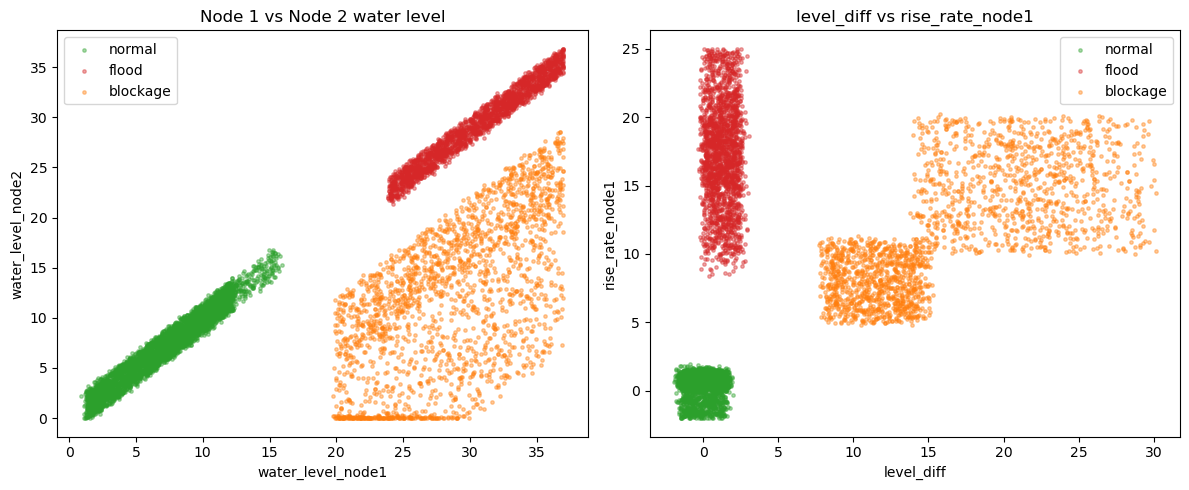

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, color in zip(CLASSES, ["tab:green", "tab:red", "tab:orange"]):
    subset = df[df["label"] == label]
    axes[0].scatter(subset["water_level_node1"], subset["water_level_node2"],
                     s=6, alpha=0.4, label=label, color=color)
    axes[1].scatter(subset["level_diff"], subset["rise_rate_node1"],
                     s=6, alpha=0.4, label=label, color=color)

axes[0].set_xlabel("water_level_node1")
axes[0].set_ylabel("water_level_node2")
axes[0].set_title("Node 1 vs Node 2 water level")
axes[0].legend()

axes[1].set_xlabel("level_diff")
axes[1].set_ylabel("rise_rate_node1")
axes[1].set_title("level_diff vs rise_rate_node1")
axes[1].legend()

plt.tight_layout()
plt.show()


## 5. Train / test split

In [7]:
encoder = LabelEncoder()
X = df[FEATURES]
y = encoder.fit_transform(df[TARGET])

print("Classes:")
for i, name in enumerate(encoder.classes_):
    print(" ", i, "->", name)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("\nTraining samples:", len(X_train), " | Testing samples:", len(X_test))


Classes:
  0 -> blockage
  1 -> flood
  2 -> normal

Training samples: 6000  | Testing samples: 1500


## 6. Train the Random Forest

In [8]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=18,
    min_samples_split=5,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1,
    oob_score=True,
)

print("Training...")
rf.fit(X_train, y_train)
print("Training complete.")
print("Out-of-bag score:", round(rf.oob_score_ * 100, 2), "%")


Training...
Training complete.
Out-of-bag score: 100.0 %


In [9]:
scores = cross_val_score(rf, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1)
print("5-fold CV accuracy scores:", scores)
print("Average CV accuracy:", round(scores.mean() * 100, 2), "%")


5-fold CV accuracy scores: [1. 1. 1. 1. 1.]
Average CV accuracy: 100.0 %


## 7. Evaluate on the held-out test set

In [10]:
y_pred = rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", round(accuracy * 100, 2), "%\n")

print(classification_report(y_test, y_pred, target_names=encoder.classes_))


Test accuracy: 100.0 %

              precision    recall  f1-score   support

    blockage       1.00      1.00      1.00       400
       flood       1.00      1.00      1.00       400
      normal       1.00      1.00      1.00       700

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500



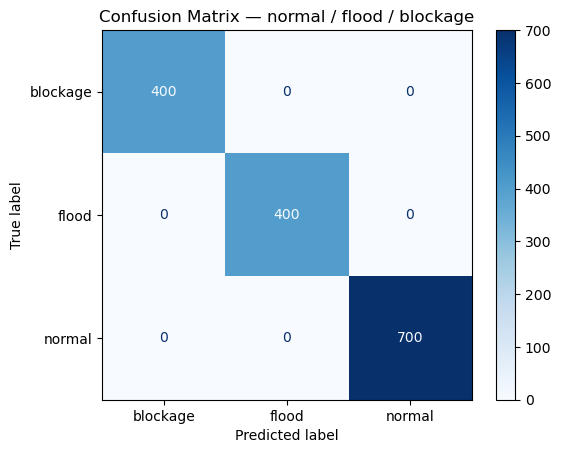

In [11]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=encoder.classes_)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix — normal / flood / blockage")
plt.show()


                         Feature  Importance
                      level_diff    0.220440
                 rise_rate_node2    0.195874
               water_level_node1    0.151355
                 rise_rate_node1    0.129148
precipitationIntensity_next_hour    0.108736
               water_level_node2    0.089813
          precipitationIntensity    0.068422
        precipitationProbability    0.036212


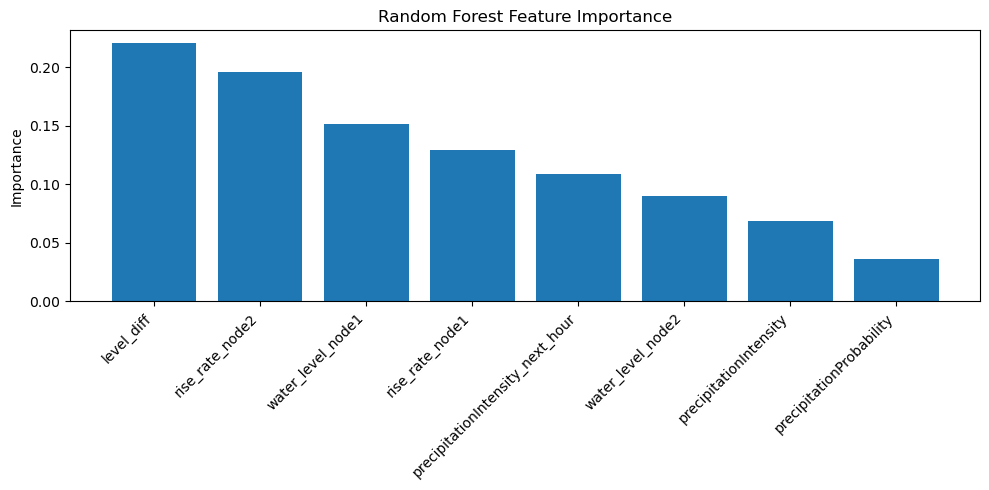

In [12]:
importance = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": rf.feature_importances_,
}).sort_values(by="Importance", ascending=False)

print(importance.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.bar(importance["Feature"], importance["Importance"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


## 8. Manual spot-check with realistic sensor values

Includes edge cases right at the sensor's `0` and `37` cm bounds, so we can confirm the model
handles the extremes correctly and not just the comfortable middle of the range.

In [17]:
demo = pd.DataFrame([
    # NORMAL — calm, low water on both nodes
    [6, 6.5, 6 - 6.5, 0.8, 0.7, 1.5, 10, 2.0],

    # NORMAL — draining after rain stopped
    [12, 11, 12 - 11, -1.2, -1.0, 0, 5, 0],

    # FLOOD — both nodes near the 37 cm ceiling, rising together
    [35, 35, 35 - 34, 0, 0, 0, 0, 80],

    # FLOOD — onset, just crossed into flood territory
    [26, 25, 26 - 25, 8, 0, 0, 0, 45],

    # BLOCKAGE — node 1 backed up near ceiling, node 2 barely moving
    [36, 5, 36 - 5, 16, 0.2, 5, 20, 5],

    # BLOCKAGE — partial blockage, smaller gap but still clearly abnormal
    [24, 12, 24 - 12, 9, 0.5, 10, 40, 12],
], columns=FEATURES)

labels_expected = ["normal", "normal", "flood", "flood", "blockage", "blockage"]

pred_idx = rf.predict(demo)
pred_labels = encoder.inverse_transform(pred_idx)
probs = rf.predict_proba(demo)

for i, (expected, predicted) in enumerate(zip(labels_expected, pred_labels)):
    mark = "OK" if expected == predicted else "MISMATCH"
    print(f"Sample {i+1}: expected={expected:9s} predicted={predicted:9s} [{mark}]")
    for cls, p in zip(encoder.classes_, probs[i]):
        print(f"    {cls:9s}: {p*100:5.2f}%")


Sample 1: expected=normal    predicted=normal    [OK]
    blockage :  0.00%
    flood    :  0.00%
    normal   : 100.00%
Sample 2: expected=normal    predicted=normal    [OK]
    blockage :  0.00%
    flood    :  0.00%
    normal   : 100.00%
Sample 3: expected=flood     predicted=normal    [MISMATCH]
    blockage : 25.19%
    flood    : 22.11%
    normal   : 52.71%
Sample 4: expected=flood     predicted=blockage  [MISMATCH]
    blockage : 43.61%
    flood    : 32.06%
    normal   : 24.33%
Sample 5: expected=blockage  predicted=blockage  [OK]
    blockage : 100.00%
    flood    :  0.00%
    normal   :  0.00%
Sample 6: expected=blockage  predicted=blockage  [OK]
    blockage : 100.00%
    flood    :  0.00%
    normal   :  0.00%


## 9. Reusable prediction helper (matches `server/prediction.py`'s contract)

In [1]:
def predict_condition(
    water_level_node1,
    water_level_node2,
    rise_rate_node1,
    rise_rate_node2,
    precipitationIntensity,
    precipitationProbability,
    precipitationIntensity_next_hour,
):
    level_diff = water_level_node1 - water_level_node2

    sample = pd.DataFrame([[
        water_level_node1, water_level_node2, level_diff,
        rise_rate_node1, rise_rate_node2,
        precipitationIntensity, precipitationProbability, precipitationIntensity_next_hour,
    ]], columns=FEATURES)

    prediction = encoder.inverse_transform(rf.predict(sample))[0]
    probs = dict(zip(encoder.classes_, rf.predict_proba(sample)[0]))

    return {
        "prediction": prediction,
        "flood_probability": round(probs["flood"] * 100, 2),
        "blockage_probability": round(probs["blockage"] * 100, 2),
        "normal_probability": round(probs["normal"] * 100, 2),
    }


predict_condition(
    water_level_node1=30, water_level_node2=28,
    rise_rate_node1=11, rise_rate_node2=10,
    precipitationIntensity=50, precipitationProbability=95,
    precipitationIntensity_next_hour=60,
)


NameError: name 'pd' is not defined

## 10. Save & deploy

Saves `model.joblib` / `encoder.joblib` to `model_training/manhole_model_output/` and copies
them straight into `server/models/`, exactly like `train_model.py` does — so the Flask server
picks up the new model automatically.

In [14]:
import shutil

model_path = os.path.join(OUTPUT_DIR, "model.joblib")
encoder_path = os.path.join(OUTPUT_DIR, "encoder.joblib")

joblib.dump(rf, model_path)
joblib.dump(encoder, encoder_path)
print("Saved:", model_path)
print("Saved:", encoder_path)

try:
    os.makedirs(SERVER_MODELS_DIR, exist_ok=True)
    shutil.copy2(model_path, os.path.join(SERVER_MODELS_DIR, "model.joblib"))
    shutil.copy2(encoder_path, os.path.join(SERVER_MODELS_DIR, "encoder.joblib"))
    print("Deployed to:", SERVER_MODELS_DIR)
except Exception as exc:
    print("Could not auto-deploy (run this notebook from inside model_training/ to enable it):", exc)


Saved: manhole_model_output\model.joblib
Saved: manhole_model_output\encoder.joblib
Deployed to: ..\server\models
